# Practical 6 – Tic-Tac-Toe using Reinforcement Learning (Q-Learning)

**Problem Statement:** Build a Tic-Tac-Toe game using reinforcement learning in Python:
a. Setting up the environment  b. Defining the Tic-Tac-Toe game  c. Building the RL model
d. Training the model  e. Testing the model

**Objective:** Design and implement a Tic-Tac-Toe game where an agent learns optimal gameplay using Q-learning.

**Outcome:** Students will be able to use reinforcement learning to solve problems that are hard to solve with
conventional techniques.

**Theory:** In **Reinforcement Learning** an *agent* takes *actions* in an *environment*, moves to a new *state* and
receives a *reward*; it learns a policy that maximises cumulative reward. **Q-learning** keeps a table Q(s, a) and updates

$$Q(s,a) \leftarrow Q(s,a) + \alpha\,[\,r + \gamma \max_{a'} Q(s',a') - Q(s,a)\,]$$

with learning rate α, discount factor γ and an **ε-greedy** policy (explore randomly with probability ε, otherwise
choose the best known action). Rewards: win = +1, draw = +0.5, loss = −1.

## a. Setting up the environment

In [1]:
import random
import numpy as np
import matplotlib.pyplot as plt
from collections import defaultdict

random.seed(42)
np.random.seed(42)

## b. Defining the Tic-Tac-Toe game

In [2]:
class TicTacToe:
    WIN_LINES = [(0,1,2),(3,4,5),(6,7,8),(0,3,6),(1,4,7),(2,5,8),(0,4,8),(2,4,6)]

    def __init__(self):
        self.reset()

    def reset(self):
        self.board = [' '] * 9
        self.current = 'X'
        return self.state()

    def state(self):
        return ''.join(self.board)

    def available_actions(self):
        return [i for i, c in enumerate(self.board) if c == ' ']

    def winner(self):
        for a, b, c in self.WIN_LINES:
            if self.board[a] != ' ' and self.board[a] == self.board[b] == self.board[c]:
                return self.board[a]
        if ' ' not in self.board:
            return 'Draw'
        return None

    def step(self, action):
        assert self.board[action] == ' ', "illegal move"
        self.board[action] = self.current
        result = self.winner()
        self.current = 'O' if self.current == 'X' else 'X'
        return self.state(), result

    def render(self):
        b = [c if c != ' ' else str(i) for i, c in enumerate(self.board)]
        print(f" {b[0]} | {b[1]} | {b[2]}\n---+---+---\n {b[3]} | {b[4]} | {b[5]}\n---+---+---\n {b[6]} | {b[7]} | {b[8]}\n")

g = TicTacToe(); g.render()

 0 | 1 | 2
---+---+---
 3 | 4 | 5
---+---+---
 6 | 7 | 8



## c. Building the reinforcement learning model (Q-learning agent)

In [3]:
class QLearningAgent:
    def __init__(self, symbol, alpha=0.3, gamma=0.9, epsilon=1.0):
        self.symbol = symbol
        self.alpha, self.gamma, self.epsilon = alpha, gamma, epsilon
        self.Q = defaultdict(float)          # Q[(state, action)]

    def choose_action(self, state, actions, greedy=False):
        if not greedy and random.random() < self.epsilon:
            return random.choice(actions)
        qs = [self.Q[(state, a)] for a in actions]
        best = max(qs)
        return random.choice([a for a, q in zip(actions, qs) if q == best])

    def update(self, state, action, reward, next_state, next_actions, done):
        target = reward
        if not done and next_actions:
            target += self.gamma * max(self.Q[(next_state, a)] for a in next_actions)
        self.Q[(state, action)] += self.alpha * (target - self.Q[(state, action)])

REWARD = {'win': 1.0, 'draw': 0.5, 'loss': -1.0}

## d. Training the model
Two Q-learning agents (X and O) learn by playing against each other (**self-play**). After each move the agent that moved
is updated with the value of the position it will face on its next turn; at the end of the game both get the final reward.
ε decays from 1.0 (pure exploration) to 0.01.

Training finished. Q-table sizes: {'X': 8631, 'O': 7536}


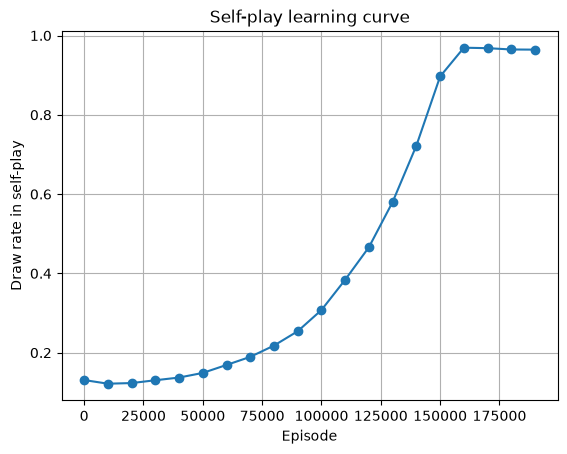

In [4]:
def train(episodes=60000):
    env = TicTacToe()
    agents = {'X': QLearningAgent('X'), 'O': QLearningAgent('O')}
    history = []
    for ep in range(episodes):
        eps = max(0.01, 1.0 - ep / (0.8 * episodes))
        for ag in agents.values():
            ag.epsilon = eps
        state = env.reset()
        last = {'X': None, 'O': None}            # (state, action) of each player's previous move
        while True:
            player = env.current
            agent = agents[player]
            actions = env.available_actions()
            # update this player's previous move now that we know the state it led to
            if last[player]:
                s, a = last[player]
                agent.update(s, a, 0.0, state, actions, done=False)
            action = agent.choose_action(state, actions)
            last[player] = (state, action)
            state, result = env.step(action)
            if result:
                other = 'O' if player == 'X' else 'X'
                if result == 'Draw':
                    r_player, r_other = REWARD['draw'], REWARD['draw']
                else:
                    r_player, r_other = REWARD['win'], REWARD['loss']
                agent.update(*last[player], r_player, None, [], done=True)
                if last[other]:
                    agents[other].update(*last[other], r_other, None, [], done=True)
                history.append(result)
                break
    return agents, history

agents, history = train(episodes=200000)
print("Training finished. Q-table sizes:", {k: len(v.Q) for k, v in agents.items()})

# learning curve: draw rate per 2000 games (perfect players always draw)
window = 10000
draw_rate = [history[i:i+window].count('Draw') / window for i in range(0, len(history), window)]
plt.plot(np.arange(len(draw_rate)) * window, draw_rate, marker='o')
plt.xlabel("Episode"); plt.ylabel("Draw rate in self-play"); plt.title("Self-play learning curve"); plt.grid(True)
plt.show()

## e. Testing the model

In [5]:
def play(agent_x, agent_o, games=1000):
    """agent_x / agent_o: a QLearningAgent (plays greedily) or None for a random player."""
    env = TicTacToe()
    results = {'X': 0, 'O': 0, 'Draw': 0}
    for _ in range(games):
        state = env.reset()
        while True:
            ag = agent_x if env.current == 'X' else agent_o
            actions = env.available_actions()
            a = ag.choose_action(state, actions, greedy=True) if ag else random.choice(actions)
            state, result = env.step(a)
            if result:
                results[result] += 1
                break
    return results

X, O = agents['X'], agents['O']
r1 = play(X, None)
r2 = play(None, O)
r3 = play(X, O, games=100)
print("Trained X vs Random O :", r1, f"-> win+draw rate = {(r1['X']+r1['Draw'])/10:.1f}%")
print("Random X vs Trained O :", r2, f"-> win+draw rate = {(r2['O']+r2['Draw'])/10:.1f}%")
print("Trained X vs Trained O:", r3, "(optimal play always ends in a draw)")

Trained X vs Random O : {'X': 954, 'O': 0, 'Draw': 46} -> win+draw rate = 100.0%
Random X vs Trained O : {'X': 0, 'O': 899, 'Draw': 101} -> win+draw rate = 100.0%
Trained X vs Trained O: {'X': 0, 'O': 0, 'Draw': 100} (optimal play always ends in a draw)


In [6]:
# Watch one game: trained X vs random O
env = TicTacToe(); state = env.reset()
while True:
    if env.current == 'X':
        a = X.choose_action(state, env.available_actions(), greedy=True)
    else:
        a = random.choice(env.available_actions())
    print(f"{env.current} plays {a}")
    state, result = env.step(a)
    env.render()
    if result:
        print("Result:", result if result == 'Draw' else f"{result} wins")
        break

X plays 7
 0 | 1 | 2
---+---+---
 3 | 4 | 5
---+---+---
 6 | X | 8

O plays 1
 0 | O | 2
---+---+---
 3 | 4 | 5
---+---+---
 6 | X | 8

X plays 5
 0 | O | 2
---+---+---
 3 | 4 | X
---+---+---
 6 | X | 8

O plays 2
 0 | O | O
---+---+---
 3 | 4 | X
---+---+---
 6 | X | 8

X plays 0
 X | O | O
---+---+---
 3 | 4 | X
---+---+---
 6 | X | 8

O plays 4
 X | O | O
---+---+---
 3 | O | X
---+---+---
 6 | X | 8

X plays 6
 X | O | O
---+---+---
 3 | O | X
---+---+---
 X | X | 8

O plays 3
 X | O | O
---+---+---
 O | O | X
---+---+---
 X | X | 8

X plays 8
 X | O | O
---+---+---
 O | O | X
---+---+---
 X | X | X

Result: X wins


### Play against the trained agent yourself (you are O)
Set `PLAY = True` and run the cell.

In [7]:
PLAY = False
if PLAY:
    env = TicTacToe(); state = env.reset()
    while True:
        if env.current == 'X':
            a = X.choose_action(state, env.available_actions(), greedy=True)
            print("Agent plays", a)
        else:
            env.render()
            a = int(input(f"Your move {env.available_actions()}: "))
        state, result = env.step(a)
        if result:
            env.render(); print("Result:", result); break

**Conclusion:** Using Q-learning with ε-greedy exploration and self-play, the agent learned Tic-Tac-Toe from rewards only,
without any hand-written strategy. In testing it wins or draws almost every game against a random player and two trained agents draw, which is the
optimal result for Tic-Tac-Toe.